# MLP model

A sparse one-hot/scaled-numeric MLP with 64 → 32 hidden layers and scaled rent targets. Three predeclared seeds assess stability. Epochs are chosen using an internal chronological validation block, never sklearn’s random early-stopping split. Seed 42 is fixed for final selection.

Run notebooks 06–10 in order. Existing notebooks 01–05 and processed datasets are read-only inputs. Results are written to `experiments/results/`. Scores use individual rents in SGD; tuning folds are July–December 2023 and January–June 2024. No final-block scores are used in model or feature selection.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / "data/train.csv").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from experiments import rental_experiments as exp


## Model configuration

Numeric gaps are imputed from training medians, then standardized; categories use sparse one-hot encoding with fold-fitted rare-category pooling. Rent targets are standardized inside training. The network has 64 → 32 ReLU units, Adam with learning rate 0.001, L2 regularization 0.01, and batches of 1,024. Up to 40 internal epochs are tested, stopping after six stale epochs. The final refit uses the selected epoch count.

The seeds below are fixed in advance: seed 42 supplies the selected model; the others describe variability. Shared code is in `experiments/rental_experiments.py`.

In [2]:
CONFIGS = [{"random_state": seed} for seed in [42, 123, 2026]]
scores = exp.model_experiment("mlp", configs=CONFIGS, groups=[])
display(scores)
display(scores.groupby(["group", "params"])[["RMSE", "MAE", "seconds"]].mean())

mlp keep_all block_recovery base {'random_state': 42} 2023_H2: RMSE=618.967; 5.2s


mlp keep_all block_recovery base {'random_state': 42} 2024_H1: RMSE=601.005; 8.5s


mlp keep_all block_recovery base {'random_state': 123} 2023_H2: RMSE=657.652; 6.8s


mlp keep_all block_recovery base {'random_state': 123} 2024_H1: RMSE=605.046; 7.5s


mlp keep_all block_recovery base {'random_state': 2026} 2023_H2: RMSE=653.828; 6.5s


mlp keep_all block_recovery base {'random_state': 2026} 2024_H1: RMSE=624.986; 8.4s


,model,policy,imputation,group,params,fold,RMSE,MAE,bias_actual_minus_predicted,selected_iterations,internal_rmse_curve,train_rows,evaluation_rows,seconds
0,mlp,keep_all,block_recovery,base,"{""random_state"": 42}",2023_H2,618.966701,468.606083,-169.425695,1,"[627.5242414032499, 627.520766789633, 631.4830...",87937,17900,5.173368
1,mlp,keep_all,block_recovery,base,"{""random_state"": 42}",2024_H1,601.005134,438.037304,-292.830619,2,"[600.3221685476307, 594.4464504163606, 605.245...",105837,18179,8.525447
2,mlp,keep_all,block_recovery,base,"{""random_state"": 123}",2023_H2,657.652101,497.209048,-259.322397,2,"[629.7320885476445, 627.7944855268379, 631.565...",87937,17900,6.816970
3,mlp,keep_all,block_recovery,base,"{""random_state"": 123}",2024_H1,605.046001,441.482290,-297.662051,1,"[634.8178638420469, 644.6490894011296, 658.209...",105837,18179,7.507790
4,mlp,keep_all,block_recovery,base,"{""random_state"": 2026}",2023_H2,653.828434,492.734145,-259.701129,2,"[629.4632136759202, 626.7815594079897, 631.417...",87937,17900,6.531353
5,mlp,keep_all,block_recovery,base,"{""random_state"": 2026}",2024_H1,624.986317,457.793220,-342.930961,2,"[600.7155436319312, 599.6619158930209, 607.978...",105837,18179,8.384589


RMSE         MAE   seconds
group params                                                  
base  {"random_state": 123}   631.349051  469.345669  7.162380
      {"random_state": 2026}  639.407375  475.263682  7.457971
      {"random_state": 42}    609.985918  453.321693  6.849408

In [3]:
import json
display(json.loads((exp.OUT / "mlp_selection.json").read_text()))

{'model': 'mlp',
 'params': {'random_state': 42},
 'group': 'base',
 'policy': 'keep_all',
 'imputation': 'block_recovery',
 'mean_RMSE': 609.985917722512,
 'feature_selection_rule': 'Minimum earlier-fold mean RMSE; retain base if improvement <1 SGD.',
 'seed_policy': 'MLP uses predeclared seed 42; other seeds are stability diagnostics.'}

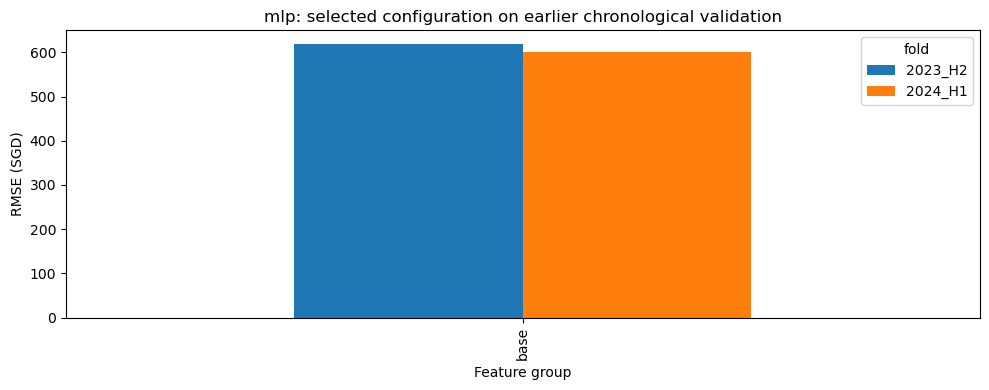

In [4]:
selected = json.loads((exp.OUT / "mlp_selection.json").read_text())
fixed = scores[scores.params.eq(json.dumps(selected["params"], sort_keys=True))]
summary = fixed.groupby(["group", "fold"]).RMSE.mean().unstack("fold")
summary.plot.bar(figsize=(10, 4))
plt.ylabel("RMSE (SGD)")
plt.xlabel("Feature group")
plt.title("mlp: selected configuration on earlier chronological validation")
plt.tight_layout()
plt.show()

## Interpretation

Read per-fold scores before interpreting the mean. A lower score does not establish causality. Explain temporal drift, duplicate uncertainty, snapshot limitations, and computational cost in the report. Hyperparameters and selections are saved alongside results.

References: [CatBoost fit API](https://catboost.ai/docs/en/concepts/python-reference_catboostregressor_fit); [scikit-learn MLPRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html).